# Anchor coverage and RPN recall: Rubin vs RubinUps vs PS13

Per-object measurements from `compute_anchor_recall.py` (job 22534368) on the full
4,285-image validation set, 127,464 truth objects, identical across the three models:

- `best_anchor_iou`: the best IoU between the object's box and **any** anchor the RPN lays down (pure geometry, no training involved).
- `best_prop_iou`: the best IoU between the box and the trained RPN's post-NMS proposals.

The RPN labels an anchor positive at IoU ≥ 0.7 and negative below 0.3. An object whose best anchor is below 0.3
is only ever trained through detectron2's forced low-quality match.

The question: does the RPN's anchor grid explain (1) PS13's bright-end completeness loss and
(2) any part of the RubinUps-over-baseline gain?

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image, display

ROOT = os.path.expanduser('~/lsst_runs')
OUT = './metrics_plots/anchor_recall'
os.makedirs(OUT, exist_ok=True)

# colours follow plot_binned_metrics.RUN_COLORS order, so these match the paper figures
CFG_DIR = '/u/yse2/deepdisc/configs/solo'
MODELS = {
    'Rubin':    dict(run='lsst5_30k_4h200_bs192_ep50',          color='#006BA4', ls='-',  marker='o',
                     pix=0.2,    canvas=160, strides=[4, 8, 16, 32, 64],
                     cfgfile=f'{CFG_DIR}/swin_lsst_30k.py'),
    'RubinUps': dict(run='lsst5_ups_30k_4h200_bs192_ep50',      color='#1baf7a', ls='--', marker='s',
                     pix=0.0575, canvas=512, strides=[4, 8, 16, 32, 64],
                     cfgfile=f'{CFG_DIR}/swin_ups_lsst_30k.py'),
    'PS13':     dict(run='lsst5_ps13_ups_30k_4h200_bs192_ep50', color='#AA3377', ls='-.', marker='^',
                     pix=0.0575, canvas=520, strides=[13, 26, 52, 104, 208],
                     cfgfile=f'{CFG_DIR}/swin_ps13_ups_lsst_30k.py'),
}
ANCHOR_SIZES = [8, 16, 32, 64, 128]  # px, identical in all three configs
MATCHER_NEG, MATCHER_POS = 0.3, 0.7   # RPN anchor_matcher thresholds
M_CUT = 25.3
MAG_EDGES = np.arange(18.3, 27.3 + 1e-6, 0.5)  # same edges as plot_binned_metrics (m_cut on an edge)
IMG_ARCSEC = 512 * 0.0575  # sky extent of one cutout, 29.4"

dfs = {m: pd.read_csv(f"{ROOT}/{c['run']}/metrics/anchor_recall/anchor_recall_{c['run']}.csv")
       for m, c in MODELS.items()}
ref = dfs['Rubin']['obj_id'].to_numpy()
assert all((d['obj_id'].to_numpy() == ref).all() for d in dfs.values()), 'object order differs'
print({m: len(d) for m, d in dfs.items()}, '— same objects, same order')

plt.rcParams.update({'font.size': 10, 'axes.spines.top': False, 'axes.spines.right': False,
                     'axes.grid': True, 'grid.alpha': 0.25, 'grid.linewidth': 0.6,
                     'lines.linewidth': 1.8, 'lines.markersize': 4, 'legend.frameon': False,
                     'figure.dpi': 110, 'savefig.dpi': 200, 'savefig.bbox': 'tight'})
INK, MUTED = '#222222', '#6b6b6b'

def style(m):
    c = MODELS[m]
    return dict(color=c['color'], ls=c['ls'], marker=c['marker'], label=m)

def binned(x, y, edges, fn, min_n=20):
    idx = np.digitize(x, edges) - 1
    out = np.full(len(edges) - 1, np.nan)
    for b in range(len(edges) - 1):
        sel = y[idx == b]
        if len(sel) >= min_n:
            out[b] = fn(sel)
    return out

def counts(x, edges):
    return np.histogram(x, edges)[0]

{'Rubin': 127464, 'RubinUps': 127464, 'PS13': 127464} — same objects, same order


## 1. The configs: same anchors, different strides

All three models use anchors of 8–128 px with aspect ratios 0.5, 1 and 2. What changes is the stride of the
pyramid level each anchor sits on, and the pixel scale that turns pixels into arcseconds.

In [2]:
rows = []
for m, c in MODELS.items():
    d = dfs[m]
    rows.append({
        'model': m,
        'canvas (px)': c['canvas'],
        'strides (px)': c['strides'],
        'anchor / stride': ANCHOR_SIZES[0] / c['strides'][0],
        'largest anchor (″)': 128 * c['pix'],
        'median best-anchor IoU': d.best_anchor_iou.median(),
        f'best anchor IoU below {MATCHER_NEG}': (d.best_anchor_iou < MATCHER_NEG).mean(),
        f'best anchor IoU ≥ {MATCHER_POS}': (d.best_anchor_iou >= MATCHER_POS).mean(),
        'RPN recall @0.5': (d.best_prop_iou >= 0.5).mean(),
        'RPN recall @0.7': (d.best_prop_iou >= 0.7).mean(),
    })
summary = pd.DataFrame(rows).set_index('model')
summary.style.format({c: '{:.1%}' for c in summary.columns if 'best anchor' in c or 'recall' in c}
                     | {'anchor / stride': '{:.2f}', 'largest anchor (″)': '{:.1f}',
                        'median best-anchor IoU': '{:.3f}'})

,canvas (px),strides (px),anchor / stride,largest anchor (″),median best-anchor IoU,best anchor IoU below 0.3,best anchor IoU ≥ 0.7,RPN recall @0.5,RPN recall @0.7
model,,,,,,,,,
Rubin,160,"[4, 8, 16, 32, 64]",2.00,25.6,0.557,0.0%,12.4%,98.7%,79.7%
RubinUps,512,"[4, 8, 16, 32, 64]",2.00,7.4,0.563,0.2%,11.5%,99.0%,87.9%
PS13,520,"[13, 26, 52, 104, 208]",0.62,7.4,0.267,63.0%,0.6%,89.7%,54.0%


### Paper sample (i < 25.3)

The table above covers every object down to i = 27.3, including the buffer. The paper evaluates at i < 25.3, so
quote these numbers there. The last two columns isolate boxes larger than 13.4″, the only objects where the Rubin
and RubinUps anchor grids differ.

In [3]:
big = dfs['Rubin'].gt_size_arcsec > 13.4  # same objects, same order in all three tables
rows = []
for m, d in dfs.items():
    g = d.mag_i < M_CUT
    rows.append({
        'model': m,
        'objects': g.sum(),
        'median best-anchor IoU': d.best_anchor_iou[g].median(),
        f'best anchor IoU below {MATCHER_NEG}': (d.best_anchor_iou[g] < MATCHER_NEG).mean(),
        'RPN recall @0.5': (d.best_prop_iou[g] >= 0.5).mean(),
        'RPN recall @0.7': (d.best_prop_iou[g] >= 0.7).mean(),
        'boxes > 13.4″': (g & big).sum(),
        'RPN recall @0.5, boxes > 13.4″': (d.best_prop_iou[g & big] >= 0.5).mean(),
    })
paper = pd.DataFrame(rows).set_index('model')
paper.style.format({c: '{:.1%}' for c in paper.columns if 'IoU below' in c or 'recall' in c}
                   | {'median best-anchor IoU': '{:.3f}', 'objects': '{:,}', 'boxes > 13.4″': '{:,}'})

,objects,median best-anchor IoU,best anchor IoU below 0.3,RPN recall @0.5,RPN recall @0.7,boxes > 13.4″,"RPN recall @0.5, boxes > 13.4″"
model,,,,,,,
Rubin,"52,975",0.571,0.0%,98.7%,87.8%,256,100.0%
RubinUps,"52,975",0.591,0.5%,98.7%,89.4%,256,83.2%
PS13,"52,975",0.255,67.8%,81.5%,47.7%,256,1.2%


## 2. What the strides do to anchor coverage

Each bar is one anchor's footprint along one image axis, drawn on the sky in arcseconds. At patch size 4 each
anchor is twice its stride, so neighbours overlap. At patch size 13 it is 0.62× its stride, so there are gaps
at **every** level, not only the coarsest. Bars alternate between two heights so overlaps stay visible.

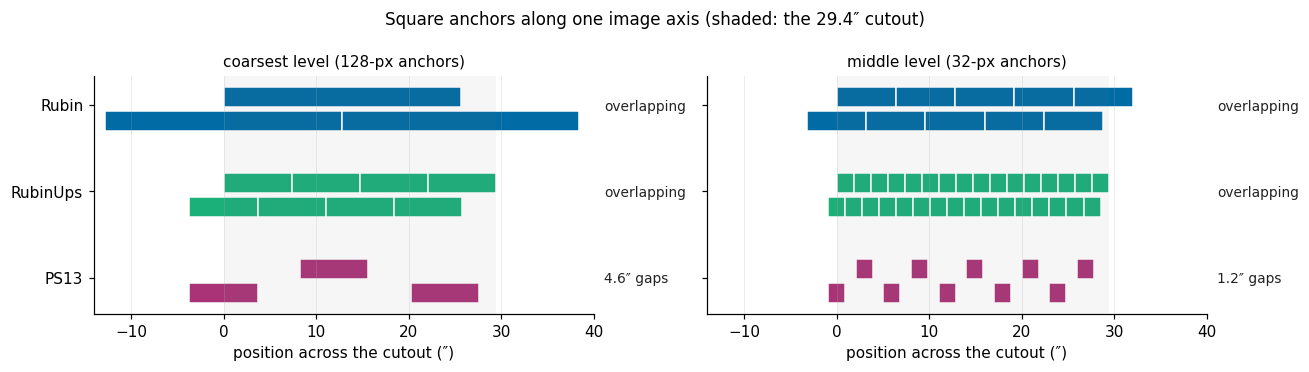

In [4]:
levels = [(4, 'coarsest level (128-px anchors)'), (2, 'middle level (32-px anchors)')]
fig, axes = plt.subplots(1, 2, figsize=(12, 3.4), sharey=True)
for ax, (lvl, title) in zip(axes, levels):
    for row, (m, c) in enumerate(MODELS.items()):
        size, stride = ANCHOR_SIZES[lvl], c['strides'][lvl]
        n = int(np.ceil(c['canvas'] / stride))
        y0 = 2 - row
        for i in range(n):
            lo = (i * stride - size / 2) * c['pix']  # anchor offset = 0: centres at i * stride
            ax.broken_barh([(lo, size * c['pix'])], (y0 + 0.28 * (i % 2) - 0.3, 0.24),
                           facecolor=c['color'], edgecolor='white', linewidth=1)
        gap = (stride - size) * c['pix']
        txt = f'{gap:.1f}″ gaps' if gap > 0 else 'overlapping'
        # label in the right margin so it never sits on a bar
        ax.text(1.02, y0 - 0.02, txt, va='center', fontsize=9, color=INK,
                transform=ax.get_yaxis_transform(), clip_on=False)
    ax.axvspan(0, IMG_ARCSEC, color='0.5', alpha=0.07, lw=0)
    ax.set_xlim(-14, 40)  # native 128-px anchors span 25.6″, centred at 0, 12.8, 25.6″
    ax.set_title(title, fontsize=10)
    ax.set_xlabel('position across the cutout (″)')
    ax.grid(axis='y', visible=False)
axes[0].set_yticks([2, 1, 0], list(MODELS))
fig.suptitle('Square anchors along one image axis (shaded: the 29.4″ cutout)', fontsize=11)
fig.tight_layout()
fig.savefig(f'{OUT}/anchor_footprints.png')
plt.show()

## 3. Best-anchor IoU for every object

This is geometry only: before any training, how well does the best available anchor fit each truth box?
Rubin and RubinUps sit almost entirely between the two matcher thresholds. PS13 shifts left, and most of its
objects fall below 0.3.

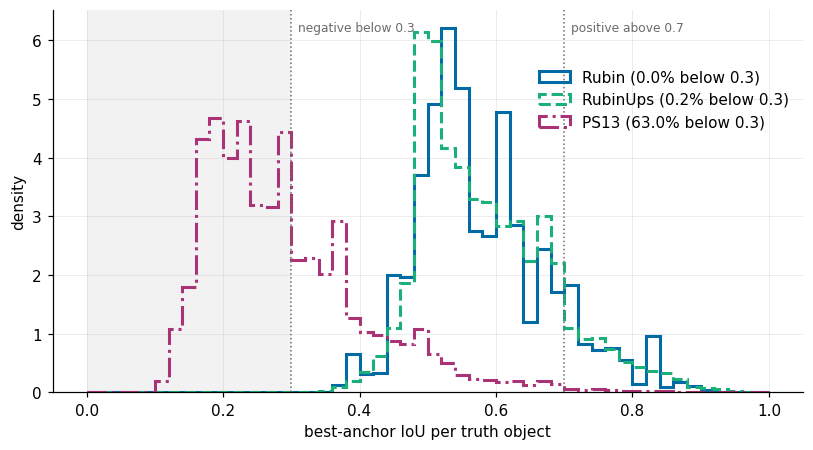

In [5]:
fig, ax = plt.subplots(figsize=(7.5, 4.2))
bins = np.linspace(0, 1, 51)
for m, d in dfs.items():
    s = style(m)
    ax.hist(d.best_anchor_iou, bins=bins, density=True, histtype='step', lw=2,
            color=s['color'], ls=s['ls'], label=f"{m} ({(d.best_anchor_iou < MATCHER_NEG).mean():.1%} below 0.3)")
ax.axvspan(0, MATCHER_NEG, color='0.5', alpha=0.1, lw=0)
for thr, name in [(MATCHER_NEG, 'negative below'), (MATCHER_POS, 'positive above')]:
    ax.axvline(thr, color=MUTED, ls=':', lw=1)
    ax.text(thr + 0.01, 0.97, f'{name} {thr}', transform=ax.get_xaxis_transform(),
            fontsize=8, color=MUTED, va='top')
ax.set_xlabel('best-anchor IoU per truth object')
ax.set_ylabel('density')
ax.legend(loc='upper right', bbox_to_anchor=(1.0, 0.88))  # empty high-IoU corner
fig.tight_layout()
fig.savefig(f'{OUT}/anchor_iou_hist.png')
plt.show()

## 4. Coverage against physical object size

Box sizes are converted to arcseconds so the native and upsampled grids line up (Rubin objects are 3.48× smaller
in pixels). Dotted lines mark the largest anchor's sky size on each grid. For a square box, the largest square
anchor's IoU drops below 0.3 once the box is larger than 128/√0.3 ≈ 234 px, which is **13.4″** on the upsampled
grid and 46.7″ on the native one.

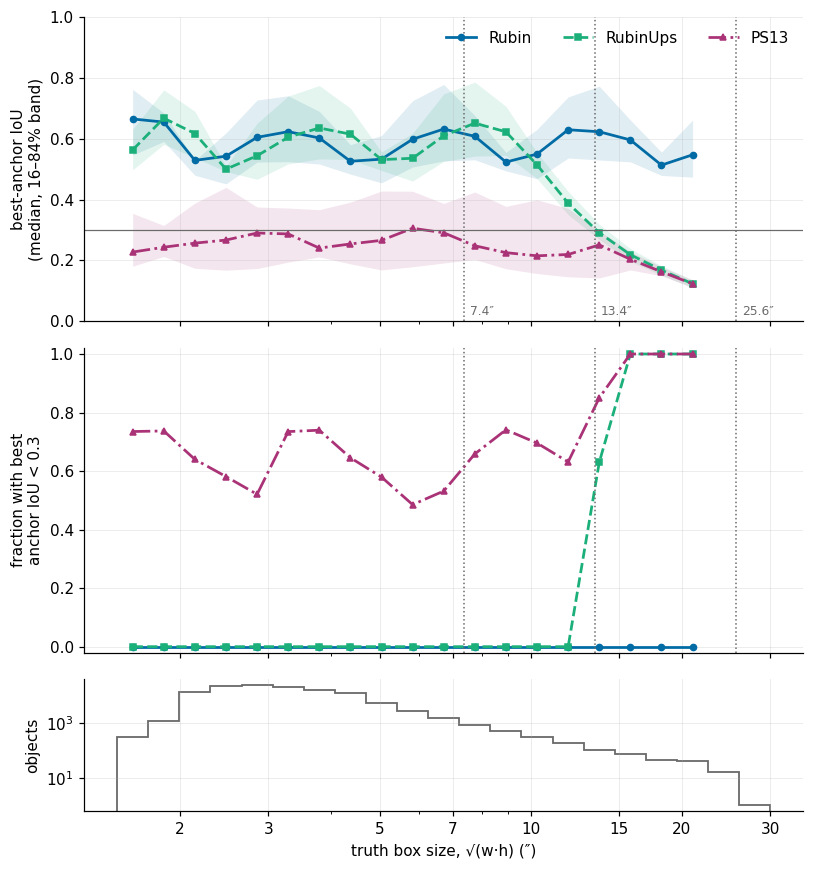

objects larger than 13.4″: 256 (0.20% of all), median i = 16.5


In [6]:
size_edges = np.geomspace(1.5, 30, 22)
size_cen = np.sqrt(size_edges[:-1] * size_edges[1:])
fig, axes = plt.subplots(3, 1, figsize=(7.5, 8), sharex=True, gridspec_kw={'height_ratios': [3, 3, 1.3]})
for m, d in dfs.items():
    s = style(m)
    x, y = d.gt_size_arcsec.to_numpy(), d.best_anchor_iou.to_numpy()
    med = binned(x, y, size_edges, np.median)
    lo = binned(x, y, size_edges, lambda v: np.quantile(v, 0.16))
    hi = binned(x, y, size_edges, lambda v: np.quantile(v, 0.84))
    axes[0].plot(size_cen, med, **s)
    axes[0].fill_between(size_cen, lo, hi, color=s['color'], alpha=0.12, lw=0)
    axes[1].plot(size_cen, binned(x, y, size_edges, lambda v: (v < MATCHER_NEG).mean()), **s)
axes[2].stairs(counts(dfs['Rubin'].gt_size_arcsec, size_edges), size_edges, color=MUTED, lw=1.2)

for ax in axes[:2]:
    for xv, txt in [(128 * 0.0575, 'largest anchor, upsampled 7.4″'), (13.4, 'IoU < 0.3 beyond 13.4″'),
                    (128 * 0.2, 'largest anchor, native 25.6″')]:
        ax.axvline(xv, color=MUTED, ls=':', lw=1)
for xv, txt in [(128 * 0.0575, '7.4″'), (13.4, '13.4″'), (128 * 0.2, '25.6″')]:
    axes[0].text(xv * 1.03, 0.02, txt, fontsize=8, color=MUTED)
axes[0].axhline(MATCHER_NEG, color=MUTED, lw=0.8)
axes[0].set_ylabel('best-anchor IoU\n(median, 16–84% band)')
axes[0].set_ylim(0, 1)
axes[1].set_ylabel(f'fraction with best\nanchor IoU < {MATCHER_NEG}')
axes[1].set_ylim(-0.02, 1.02)
axes[2].set_ylabel('objects')
axes[2].set_yscale('log')
axes[2].set_xlabel('truth box size, √(w·h) (″)')
axes[2].set_xscale('log')
axes[2].set_xticks([2, 3, 5, 7, 10, 15, 20, 30], ['2', '3', '5', '7', '10', '15', '20', '30'])
axes[0].legend(loc='upper right', ncols=3)
fig.tight_layout()
fig.savefig(f'{OUT}/anchor_iou_vs_size.png')
plt.show()

big = dfs['Rubin'].gt_size_arcsec > 13.4
print(f'objects larger than 13.4″: {big.sum():,} ({big.mean():.2%} of all), '
      f'median i = {dfs["Rubin"].mag_i[big].median():.1f}')

## 5. From anchors to proposals, by magnitude

Bright objects are large (bottom panel), so size effects show up at the bright end. The top two panels are
the **trained** RPN's recall: the fraction of objects with a proposal at IoU ≥ 0.5 or ≥ 0.7. Bands are binomial ±1σ.

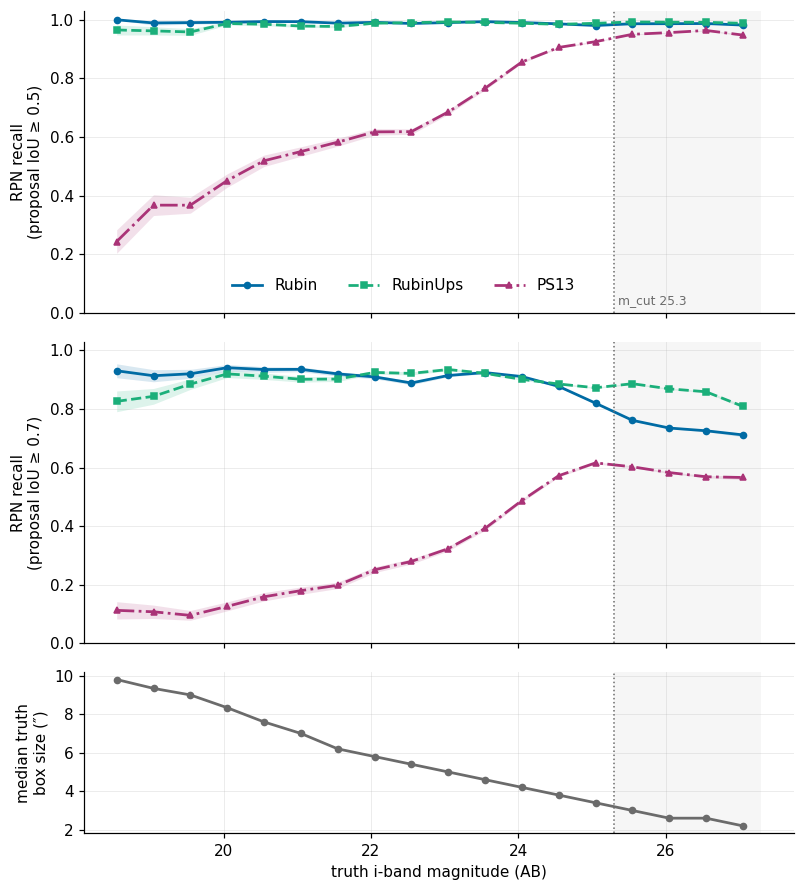

,Rubin,RubinUps,PS13
brighter than i = 20,98.9%,94.8%,28.8%
brighter than i = 22,99.2%,97.3%,49.7%
brighter than i = 25.3,98.7%,98.7%,81.5%


In [7]:
mag_cen = 0.5 * (MAG_EDGES[:-1] + MAG_EDGES[1:])
fig, axes = plt.subplots(3, 1, figsize=(7.5, 8.2), sharex=True, gridspec_kw={'height_ratios': [3, 3, 1.6]})
for m, d in dfs.items():
    s = style(m)
    x = d.mag_i.to_numpy()
    n = counts(x, MAG_EDGES)
    for ax, thr in zip(axes[:2], (0.5, 0.7)):
        p = binned(x, (d.best_prop_iou >= thr).to_numpy(), MAG_EDGES, np.mean)
        err = np.sqrt(p * (1 - p) / np.maximum(n, 1))
        ax.plot(mag_cen, p, **s)
        ax.fill_between(mag_cen, p - err, p + err, color=s['color'], alpha=0.15, lw=0)
d = dfs['Rubin']
axes[2].plot(mag_cen, binned(d.mag_i.to_numpy(), d.gt_size_arcsec.to_numpy(), MAG_EDGES, np.median),
             color=MUTED, marker='o')
for ax in axes:
    ax.axvline(M_CUT, color=MUTED, ls=':', lw=1)
    ax.axvspan(M_CUT, MAG_EDGES[-1], color='0.5', alpha=0.07, lw=0)
axes[0].text(M_CUT + 0.05, 0.03, 'm_cut 25.3', fontsize=8, color=MUTED)
axes[0].set_ylabel('RPN recall\n(proposal IoU ≥ 0.5)')
axes[1].set_ylabel('RPN recall\n(proposal IoU ≥ 0.7)')
for ax in axes[:2]:
    ax.set_ylim(0, 1.03)
axes[2].set_ylabel('median truth\nbox size (″)')
axes[2].set_xlabel('truth i-band magnitude (AB)')
axes[0].legend(loc='lower center', bbox_to_anchor=(0.45, 0.02), ncols=3)
fig.tight_layout()
fig.savefig(f'{OUT}/rpn_recall_vs_mag.png')
plt.show()

lims = (20, 22, M_CUT)
rec = pd.DataFrame({m: [(d.best_prop_iou[d.mag_i < lim] >= 0.5).mean() for lim in lims]
                    for m, d in dfs.items()}, index=[f'brighter than i = {lim}' for lim in lims])
rec.style.format('{:.1%}').set_caption('RPN recall @0.5, cumulative')

## 6. Size, not brightness

Bright objects are also large, so section 5 can't tell whether PS13 loses objects for being bright or for being
big. Splitting by both separates the two. Each cell is RPN recall at IoU 0.5 for objects in that magnitude range
(rows) and box-size range (columns). Cells with fewer than 30 objects are left blank.

If the loss is about size, recall should fall from left to right within a row and stay roughly flat from top to
bottom within a column.

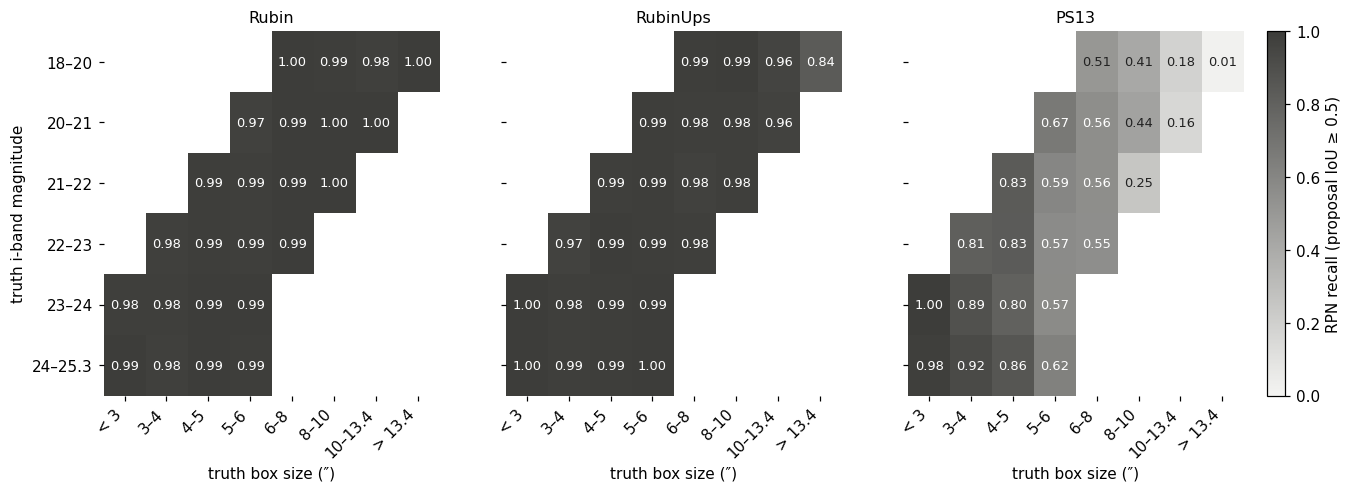

In [8]:
HEAT_MAG = [18, 20, 21, 22, 23, 24, M_CUT]
HEAT_SIZE = [0, 3, 4, 5, 6, 8, 10, 13.4, 40]
MIN_N = 30
size_labels = ['< 3'] + [f'{a:g}–{b:g}' for a, b in zip(HEAT_SIZE[1:-2], HEAT_SIZE[2:-1])] + [f'> {HEAT_SIZE[-2]:g}']
mag_labels = [f'{a:g}–{b:g}' for a, b in zip(HEAT_MAG[:-1], HEAT_MAG[1:])]
# single-hue sequential ramp, neutral so it doesn't borrow a model's identity colour
CMAP = plt.matplotlib.colors.LinearSegmentedColormap.from_list('recall', ['#f4f4f2', '#3d3d3a'])

def recall_grid(d):
    mi = np.digitize(d.mag_i, HEAT_MAG) - 1
    si = np.digitize(d.gt_size_arcsec, HEAT_SIZE) - 1
    ok = (mi >= 0) & (mi < len(HEAT_MAG) - 1) & (si >= 0) & (si < len(HEAT_SIZE) - 1)
    shape = (len(HEAT_MAG) - 1, len(HEAT_SIZE) - 1)
    n, hit = np.zeros(shape), np.zeros(shape)
    np.add.at(n, (mi[ok], si[ok]), 1)
    np.add.at(hit, (mi[ok], si[ok]), (d.best_prop_iou >= 0.5).to_numpy()[ok])
    return np.where(n >= MIN_N, hit / np.maximum(n, 1), np.nan)

fig, axes = plt.subplots(1, 3, figsize=(14, 4.3), sharey=True)
for ax, (m, d) in zip(axes, dfs.items()):
    grid = recall_grid(d)
    im = ax.imshow(grid, cmap=CMAP, vmin=0, vmax=1, aspect='auto')
    for (r, c), v in np.ndenumerate(grid):
        if np.isfinite(v):
            ax.text(c, r, f'{v:.2f}', ha='center', va='center', fontsize=8.5,
                    color='white' if v > 0.55 else INK)
    ax.set_xticks(range(len(size_labels)), size_labels, rotation=45, ha='right')
    ax.set_yticks(range(len(mag_labels)), mag_labels)
    ax.set_xlabel('truth box size (″)')
    ax.set_title(m, fontsize=10.5)
    ax.grid(False)
    for s in ax.spines.values():
        s.set_visible(False)
axes[0].set_ylabel('truth i-band magnitude')
fig.colorbar(im, ax=axes, fraction=0.025, pad=0.02, label='RPN recall (proposal IoU ≥ 0.5)')
fig.savefig(f'{OUT}/rpn_recall_mag_size.png')
plt.show()

For PS13, recall falls with size in every magnitude row: from 0.51 to 0.01 at i = 18–20, and from 1.00 to
0.57 at i = 23–24. At fixed size it is nearly flat in magnitude: the 5–6″ column reads 0.67, 0.59, 0.57, 0.57, 0.62
from bright to faint. **PS13's bright-end loss is a size effect.** Bright objects are lost because they are large.
RubinUps stays at 0.96–1.00 in every cell except the largest, brightest one (0.84), which is the case in example C
below. Rubin is flat throughout.

## 7. Compare: PS13's catalog completeness

The final completeness curve for PS13 against the padded model (from `metrics.ipynb`). Its shape follows the PS13
RPN recall above: a steep loss at the bright end that recovers by i ≈ 24.5. Completeness sits above RPN recall at
IoU 0.5 because matching uses a 1″ linking length, and the cascade heads refine proposals before matching.

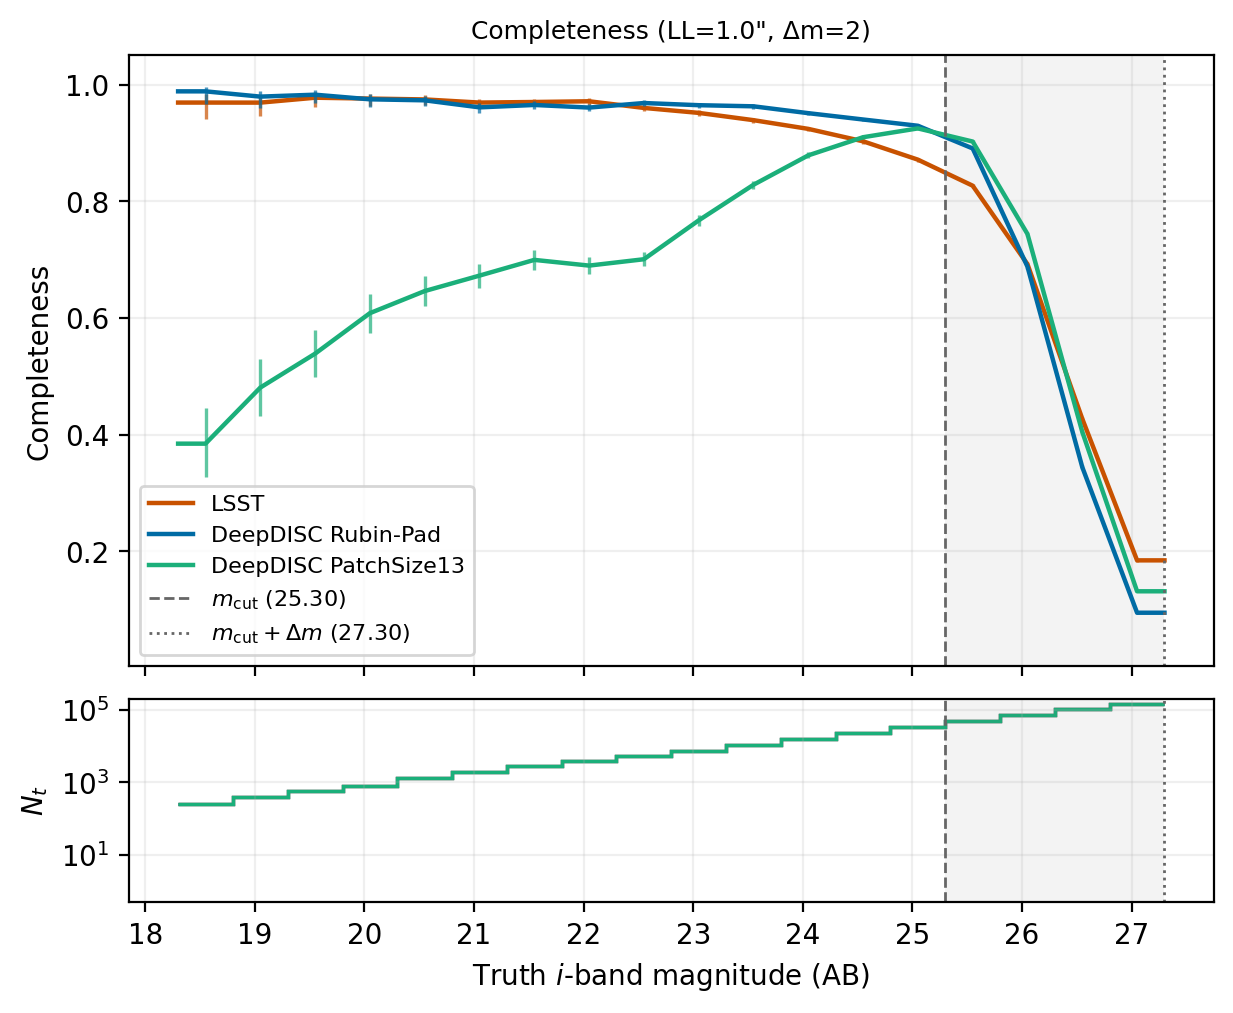

In [9]:
display(Image(filename=os.path.join(ROOT, 'lsst5_pad_30k_4h200_bs192_ep50', 'comparisons',
    'lsst5_pad_30k_4h200_bs192_ep50__vs__lsst5_ps13_ups_30k_4h200_bs192_ep50', '1.0', 'completeness_buf2.png'),
    width=620))

## 8. Visual examples

Individual objects, each drawn in all three models' input frames:

- **white box**: the truth box, from the same test mappers `compute_anchor_recall.py` used (DictMapper on the native grid; the Lanczos remap to the Roman grid for RubinUps and PS13);
- **dashed cyan box**: the best-matching anchor, with the anchors rebuilt geometrically from each config;
- **cyan dots**: the anchor centres on that anchor's pyramid level, which show how coarse the grid is.

The IoU labels are the job's per-object values. The rebuilt anchors are checked against them before plotting.

The setup cell imports detectron2 and the deepdisc mappers, which takes ~2 min on a cold start.

In [10]:
import sys, json, warnings
warnings.filterwarnings('ignore', category=UserWarning)  # detectron2's keypoint tensor warning
import matplotlib.patheffects as pe
import matplotlib.font_manager as fm
from matplotlib.patches import Rectangle
from matplotlib.lines import Line2D
from astropy.visualization import make_lupton_rgb
from mpl_toolkits.axes_grid1.anchored_artists import AnchoredSizeBar

sys.path.insert(0, '/u/yse2/deepdisc/configs')
from detectron2.config import LazyConfig
from custom.mappers import ResizeTestMapper
from deepdisc.model.loaders import DictMapper

ASPECT_RATIOS = (0.5, 1.0, 2.0)  # detectron2 default, unchanged in all three configs

def anchor_boxes(model):
    """All RPN anchors as (N, 5) [x0, y0, x1, y1, level], rebuilt like DefaultAnchorGenerator
    (offset 0). Levels 0-3 have canvas/stride cells; the top block max-pools the last one
    with stride 2, so it has ceil(n/2) cells."""
    c = MODELS[model]
    n = [c['canvas'] // s for s in c['strides'][:4]]
    n.append(-(-n[-1] // 2))
    out = []
    for lvl, (size, stride, g) in enumerate(zip(ANCHOR_SIZES, c['strides'], n)):
        cx, cy = [v.ravel() for v in np.meshgrid(np.arange(g) * stride, np.arange(g) * stride)]
        for ar in ASPECT_RATIOS:
            w = np.sqrt(size ** 2 / ar)
            h = ar * w
            out.append(np.c_[cx - w / 2, cy - h / 2, cx + w / 2, cy + h / 2, np.full(len(cx), lvl)])
    return np.concatenate(out)

def iou(boxes, box):
    ix = np.clip(np.minimum(boxes[:, 2], box[2]) - np.maximum(boxes[:, 0], box[0]), 0, None)
    iy = np.clip(np.minimum(boxes[:, 3], box[3]) - np.maximum(boxes[:, 1], box[1]), 0, None)
    inter = ix * iy
    area = (boxes[:, 2] - boxes[:, 0]) * (boxes[:, 3] - boxes[:, 1])
    return inter / (area + (box[2] - box[0]) * (box[3] - box[1]) - inter)

ANCHORS = {m: anchor_boxes(m) for m in MODELS}

val = json.load(open(os.path.expanduser('~/lsst_data/annotations_lvl5/val_4k_keypoints_wcs.json')))
DICT_OF = {a['obj_id']: d for d in val for a in d['annotations']}

RUBIN_PIX = 0.2

def build_mapper(model):
    cfg = LazyConfig.load(MODELS[model]['cfgfile'])
    t = cfg.dataloader.test
    if MODELS[model]['pix'] == RUBIN_PIX:
        return DictMapper(t.imagereader, cfg.dataloader.key_mapper, None, keypoint_hflip_indices=[0]).map_data
    return ResizeTestMapper(t.imagereader, cfg.dataloader.key_mapper, None, keypoint_hflip_indices=[0],
                            cache_dir=t.cache_dir).map_data

MAPPERS = {m: build_mapper(m) for m in ('Rubin', 'RubinUps')}
MAPPERS['PS13'] = MAPPERS['RubinUps']  # same input frame; only the anchors differ

def load_example(model, obj_id):
    """Image (C, H, W) and this object's truth box in the model's input frame."""
    out = MAPPERS[model](DICT_OF[obj_id])
    k = int(np.flatnonzero(out['instances'].gt_objid.numpy() == obj_id)[0])
    return out['image'].numpy(), out['instances'].gt_boxes.tensor[k].numpy()

### Picking examples

One example per behaviour, chosen by rule from the per-object table (galaxies only):

- **A, bright galaxy PS13 misses**: 19 < i < 21, PS13 proposal IoU < 0.3, Rubin and RubinUps proposal IoU > 0.7. Pick the lowest PS13 anchor IoU.
- **B, faint galaxy PS13 recovers**: 24 < i < 25.3, PS13 anchor IoU < 0.25 but proposal IoU > 0.75 (and > 0.7 for the other two). Pick the lowest PS13 anchor IoU.
- **C, very large galaxy on the upsampled grid**: box > 13.4″, RubinUps anchor IoU < 0.3 and proposal IoU < 0.5, Rubin proposal IoU > 0.7. Pick the largest.

All three must sit at least 3 native pixels inside the cutout. A and B must also have no other gold-sample object
(i < 25.3) centred inside their box. C can't meet that, since every box this large contains a few faint objects.
Swap in any `obj_id` from the shortlists.

In [11]:
rows = []
for d in val:
    A_ = d['annotations']
    b = np.array([a['bbox'] for a in A_], float)  # native frame, XYWH
    mag = np.array([a['mag_i'] for a in A_])
    cx, cy = b[:, 0] + b[:, 2] / 2, b[:, 1] + b[:, 3] / 2
    for k, a in enumerate(A_):
        x, y, w, h = b[k]
        inside = (cx > x) & (cx < x + w) & (cy > y) & (cy < y + h) & (mag < M_CUT)
        inside[k] = False
        rows.append((a['obj_id'], min(x, y, d['width'] - (x + w), d['height'] - (y + h)), inside.sum()))
geo = pd.DataFrame(rows, columns=['obj_id', 'edge_px', 'n_inside']).set_index('obj_id')

t = pd.DataFrame({'obj_id': dfs['Rubin'].obj_id, 'mag_i': dfs['Rubin'].mag_i,
                  'size_arcsec': dfs['Rubin'].gt_size_arcsec, 'galaxy': dfs['Rubin'].gt_class == 0,
                  **{f'anchor_{m}': d.best_anchor_iou for m, d in dfs.items()},
                  **{f'prop_{m}': d.best_prop_iou for m, d in dfs.items()}}).join(geo, on='obj_id')
inside_ok = (t.edge_px >= 3) & t.galaxy
isolated = inside_ok & (t.n_inside == 0)

shortlists = {
    'A': t[isolated & t.mag_i.between(19, 21) & (t.prop_PS13 < 0.3) & (t.prop_Rubin > 0.7)
           & (t.prop_RubinUps > 0.7)].sort_values('anchor_PS13'),
    'B': t[isolated & t.mag_i.between(24, M_CUT) & (t.anchor_PS13 < 0.25) & (t.prop_PS13 > 0.75)
           & (t.prop_Rubin > 0.7) & (t.prop_RubinUps > 0.7)].sort_values('anchor_PS13'),
    'C': t[inside_ok & (t.size_arcsec > 13.4) & (t.anchor_RubinUps < 0.3) & (t.prop_RubinUps < 0.5)
           & (t.prop_Rubin > 0.7)].sort_values('size_arcsec', ascending=False),
}
LABELS = {'A': 'bright galaxy PS13 misses', 'B': 'faint galaxy PS13 recovers', 'C': 'very large galaxy'}
for tag, s in shortlists.items():
    print(f'{tag}: {LABELS[tag]} ({len(s)} candidates)')
    display(s.head(5).round(3))
EXAMPLES = [(tag, int(s.obj_id.iloc[0]), LABELS[tag]) for tag, s in shortlists.items()]
EXAMPLES

A: bright galaxy PS13 misses (13 candidates)


,obj_id,mag_i,size_arcsec,galaxy,anchor_Rubin,anchor_RubinUps,anchor_PS13,prop_Rubin,prop_RubinUps,prop_PS13,edge_px,n_inside
88080,9500768228,20.234,9.198,True,0.516,0.497,0.157,0.920,0.866,0.253,9.5,0
47540,9500147371,20.693,7.597,True,0.691,0.557,0.196,0.899,0.865,0.220,26.5,0
103960,8625002149,20.356,7.400,True,0.567,0.737,0.204,0.884,0.921,0.296,16.5,0
101529,8625117330,19.740,12.200,True,0.733,0.363,0.206,0.917,0.819,0.239,7.5,0
30238,9500146008,19.607,12.594,True,0.671,0.338,0.212,0.913,0.875,0.281,3.5,0


B: faint galaxy PS13 recovers (3159 candidates)


,obj_id,mag_i,size_arcsec,galaxy,anchor_Rubin,anchor_RubinUps,anchor_PS13,prop_Rubin,prop_RubinUps,prop_PS13,edge_px,n_inside
39270,9504807652,25.021,3.000,True,0.540,0.611,0.146,0.712,0.933,0.875,11.5,0
17666,8627197549,25.262,3.000,True,0.605,0.540,0.149,0.749,0.790,0.803,29.5,0
111259,9504775236,25.084,2.600,True,0.543,0.490,0.151,0.798,0.801,0.783,16.5,0
121098,9500976757,25.176,3.194,True,0.699,0.537,0.151,0.832,0.835,0.786,9.5,0
8920,8625544233,25.250,2.600,True,0.660,0.490,0.153,0.736,0.826,0.796,33.5,0


C: very large galaxy (3 candidates)


,obj_id,mag_i,size_arcsec,galaxy,anchor_Rubin,anchor_RubinUps,anchor_PS13,prop_Rubin,prop_RubinUps,prop_PS13,edge_px,n_inside
84445,8687516415,17.874,19.0,True,0.454,0.149,0.149,0.827,0.377,0.108,9.5,4
121308,9500374208,19.065,13.8,True,0.524,0.281,0.281,0.748,0.426,0.254,9.5,2
97283,8625373703,19.517,13.4,True,0.872,0.296,0.296,0.774,0.326,0.342,27.5,6


[('A', 9500768228, 'bright galaxy PS13 misses'),
 ('B', 9504807652, 'faint galaxy PS13 recovers'),
 ('C', 8687516415, 'very large galaxy')]

In [12]:
# load each example in each frame, and check the rebuilt anchors against the job's values
row = {m: d.set_index('obj_id') for m, d in dfs.items()}
cache, chk = {}, []
for tag, obj, _ in EXAMPLES:
    for m in MODELS:
        img, box = cache.setdefault((m, obj), load_example(m, obj))
        ious = iou(ANCHORS[m], box)
        j = ious.argmax()
        chk.append(dict(example=tag, model=m, rebuilt_iou=ious[j], job_iou=row[m].loc[obj, 'best_anchor_iou'],
                        rebuilt_level=int(ANCHORS[m][j, 4]), job_level=int(row[m].loc[obj, 'best_anchor_level'])))
chk = pd.DataFrame(chk)
assert np.allclose(chk.rebuilt_iou, chk.job_iou, atol=1e-3) and (chk.rebuilt_level == chk.job_level).all()
chk.round(4)

,example,model,rebuilt_iou,job_iou,rebuilt_level,job_level
0,A,Rubin,0.5164,0.5164,3,3
1,A,RubinUps,0.4969,0.4969,4,4
2,A,PS13,0.1569,0.1569,3,3
3,B,Rubin,0.5404,0.5404,1,1
4,B,RubinUps,0.6108,0.6108,3,3
5,B,PS13,0.1455,0.1455,3,3
6,C,Rubin,0.4539,0.4539,3,3
7,C,RubinUps,0.1491,0.1491,4,4
8,C,PS13,0.1489,0.1489,4,4


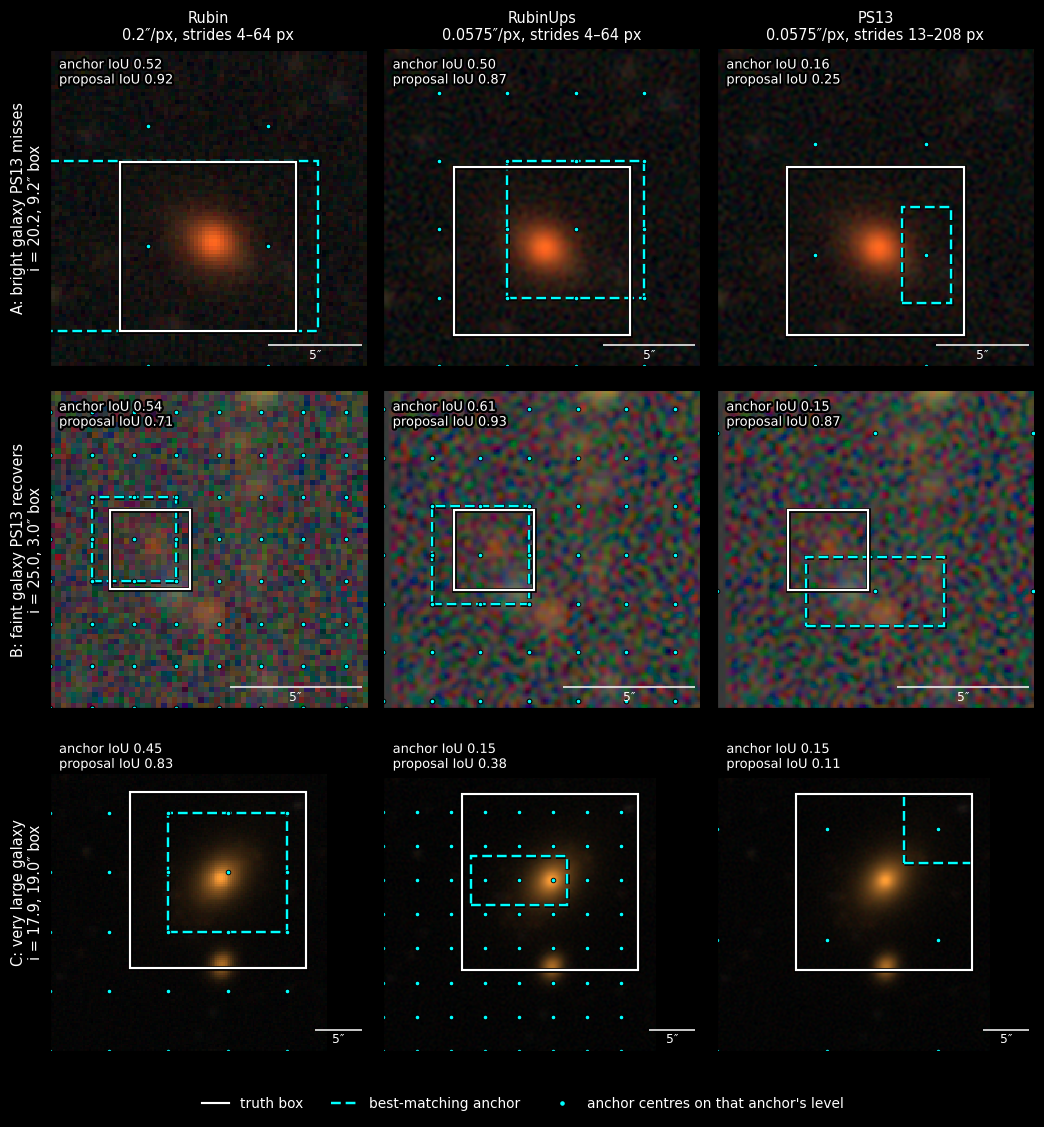

In [13]:
def make_rgb(img, bands=(3, 2, 1), Q=8):
    """i/r/g Lupton composite with a per-image percentile stretch, as in scene_plots.ipynb."""
    r, g, b = img[bands[0]], img[bands[1]], img[bands[2]]
    pmin = np.percentile([r, g, b], 1)
    stretch = np.percentile([r, g, b], 99.5) - pmin
    return make_lupton_rgb(r, g, b, minimum=pmin, stretch=stretch, Q=Q)

# on-image colours follow scene_plots.ipynb: bright hues with a black shadow, since the
# paper's model colours are hard to see on the images
ANCHOR_C = 'cyan'
SHADOW = [pe.withStroke(linewidth=3, foreground='black')]

def draw_panel(ax, model, obj):
    c = MODELS[model]
    img, box = cache[(model, obj)]
    A_ = ANCHORS[model]
    best = A_[iou(A_, box).argmax()]
    # same sky extent in every column of a row; the window is shifted, not clipped, at the cutout edge
    H, W = img.shape[1:]
    half = max(0.9 * max(box[2] - box[0], box[3] - box[1]) * c['pix'], 6.0) / c['pix']
    cx = np.clip((box[0] + box[2]) / 2, half, max(half, W - half))
    cy = np.clip((box[1] + box[3]) / 2, half, max(half, H - half))
    x0, x1 = int(max(0, cx - half)), int(min(W, cx + half))
    y0, y1 = int(max(0, cy - half)), int(min(H, cy + half))
    ax.set_facecolor('black')
    ax.imshow(make_rgb(img[:, y0:y1, x0:x1]), origin='lower', extent=(x0, x1, y0, y1), interpolation='nearest')
    level = A_[A_[:, 4] == best[4]]
    ctr = np.unique(np.c_[(level[:, 0] + level[:, 2]) / 2, (level[:, 1] + level[:, 3]) / 2], axis=0)
    ax.plot(ctr[:, 0], ctr[:, 1], 'o', ms=3, color=ANCHOR_C, mec='black', mew=0.6, ls='none')
    ax.add_patch(Rectangle(best[:2], best[2] - best[0], best[3] - best[1], fill=False, ec=ANCHOR_C,
                           lw=1.6, ls=(0, (4, 2)), path_effects=SHADOW))
    ax.add_patch(Rectangle(box[:2], box[2] - box[0], box[3] - box[1], fill=False, ec='white', lw=1.4,
                           path_effects=SHADOW))
    ax.set_xlim(cx - half, cx + half)
    ax.set_ylim(cy - half, cy + half)
    r = row[model].loc[obj]
    ax.text(0.03, 0.97, f'anchor IoU {r.best_anchor_iou:.2f}\nproposal IoU {r.best_prop_iou:.2f}',
            transform=ax.transAxes, va='top', ha='left', fontsize=8.5, color='white', path_effects=SHADOW)
    ax.add_artist(AnchoredSizeBar(ax.transData, 5 / c['pix'], '5″', loc='lower right', pad=0.3, color='white',
                                  frameon=False, size_vertical=0, fontproperties=fm.FontProperties(size=8)))
    ax.set_xticks([])
    ax.set_yticks([])

fig, axes = plt.subplots(len(EXAMPLES), 3, figsize=(9.6, 3.4 * len(EXAMPLES)), facecolor='black', squeeze=False)
for i, (tag, obj, label) in enumerate(EXAMPLES):
    r0 = row['Rubin'].loc[obj]
    for j, m in enumerate(MODELS):
        draw_panel(axes[i, j], m, obj)
        if i == 0:
            c = MODELS[m]
            axes[i, j].set_title(f"{m}\n{c['pix']}″/px, strides {c['strides'][0]}–{c['strides'][-1]} px",
                                 color='white', fontsize=9.5)
    axes[i, 0].set_ylabel(f'{tag}: {label}\ni = {r0.mag_i:.1f}, {r0.gt_size_arcsec:.1f}″ box',
                          color='white', fontsize=9.5)
handles = [Line2D([], [], color='white', lw=1.4, label='truth box'),
           Line2D([], [], color=ANCHOR_C, lw=1.6, ls=(0, (4, 2)), label='best-matching anchor'),
           Line2D([], [], color=ANCHOR_C, marker='o', ms=4, mec='black', ls='none',
                  label="anchor centres on that anchor's level")]
fig.legend(handles=handles, loc='lower center', ncols=3, frameon=False, labelcolor='white', fontsize=9,
           bbox_to_anchor=(0.5, -0.01))
fig.tight_layout(rect=(0, 0.03, 1, 1))
fig.savefig(f'{OUT}/anchor_examples.png', facecolor='black')
plt.show()

### Reading the examples (default picks)

- **A**: on both patch-4 grids, an anchor of roughly the box's size sits close to the galaxy (IoU ~0.5), and the
  RPN refines it to a proposal above 0.85. On PS13's grid no anchor of that size is centred near the galaxy. The
  best it has is a smaller anchor from the next level down, off to one side (IoU 0.16). The trained RPN doesn't
  recover it (proposal IoU 0.25), so the object is lost before the ROI heads see it.
- **B**: PS13's best anchor is just as poor, but the box is small, and the RPN regresses a nearby anchor onto it
  (proposal IoU above 0.75). This is why PS13's recall recovers toward the faint end.
- **C**: the reverse case. On the native grid the 128-px anchor spans 25.6″, so a ~19″ galaxy still has a
  well-fitting anchor. On the upsampled grid the largest anchor is 7.4″, so even the dense RubinUps grid has nothing
  close to the box's size, and RubinUps's proposal falls short. This is the small set of very large, bright objects
  where upsampling costs RubinUps, not where it gains.

## What this means for §4.2
**PS13 is a confounded control, confirmed.** 63% of all objects have no anchor at IoU ≥ 0.3, against 0.0% for Rubin and 0.2% for RubinUps (for i < 25.3: 67.8%, 0.0% and 0.5%), because each anchor is 0.62× its stride at every level. This shortfall is about the same at every object size up to 13.4″: 53–71% of objects in each size range (section 4). What depends on size is whether the trained RPN makes up for it. Its recall at IoU 0.5 is 96% for boxes under 3″, 57% at 5–8″ and 34% at 8–13.4″. At fixed magnitude recall falls with size, and at fixed size it is nearly flat in magnitude (section 6). The bright-end loss is therefore a size effect: bright objects are large, and large objects are the ones the RPN cannot recover from a poorly placed anchor. Recall at IoU 0.5 is 24% in the brightest bin and 29% for everything brighter than i = 20, against 91% at i = 24–25.3. That has the same shape as PS13's completeness curve.

**Rubin vs RubinUps:** anchor geometry does not explain the gain. In the paper's sample (i < 25.3, section 1) the two grids cover boxes equally well for 99.5% of objects (median best-anchor IoU 0.571 vs 0.591). They differ only above ~12″, where the 7.4″ upsampled anchors are too small. That affects 256 objects larger than 13.4″ (0.5% of the sample, median i = 16.5, brighter than the plotted range), and the disadvantage falls on RubinUps: its RPN recovers 83.2% of them at IoU 0.5, against 100% for Rubin (94.8% vs 98.9% for everything brighter than i = 20). Overall recall at IoU 0.5 is identical (98.7% for i < 25.3).

**Proposal tightness is not a factor within the cut.** Over all objects RubinUps's recall at IoU 0.7 is higher than Rubin's (87.9% vs 79.7%), but that gap comes almost entirely from objects fainter than m_cut. For i < 25.3 it is 89.4% vs 87.8%, and for i < 24 the two are equal (91.3% vs 91.7%).

So idt we need a restructure and can just do a paragraph rewrite of §4.2 with these figures in the appendix
